# 10 - Loss seasons: when, where, and with what weather
**Heat, Rain & Harvest.** Descriptive. A *loss season* = district yield more than 10% below its own long-run trend
(D14). Weather is compared with the same district's normal as a z-score, so "hot" means hot for that district.
Regions group Census 2011 states (`src/loss_patterns.py`). Seasons are labelled by start year: 2014 = 2014-15.
These are associations, not causal estimates; the causal estimates are the fixed-effects results (notebook 06).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import PROCESSED, FIGURES
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
save = lambda fig, n: fig.savefig(FIGURES / f"{n}.png", bbox_inches="tight", dpi=150)
P = PROCESSED / "patterns"
season = lambda y: f"{int(y)}-{(int(y) + 1) % 100:02d}"
LAB = {"z_tmin_mean": "night temp.", "z_tmax_mean": "day temp.", "z_feb_tmax_mean": "Feb day temp.",
       "z_mar_tmax_mean": "Mar day temp.", "z_mar_hot_days_35": "Mar days >=35C", "z_rain_total": "season rain",
       "z_rain_nov_jan": "Nov-Jan rain", "z_prev_monsoon_rain": "prev. monsoon rain", "z_rain_jun_sep": "Jun-Sep rain",
       "z_longest_dry_spell": "longest dry spell", "z_rainy_days": "rainy days", "z_hot_days_35": "days >=35C"}

## 1. Which seasons were bad, and where?

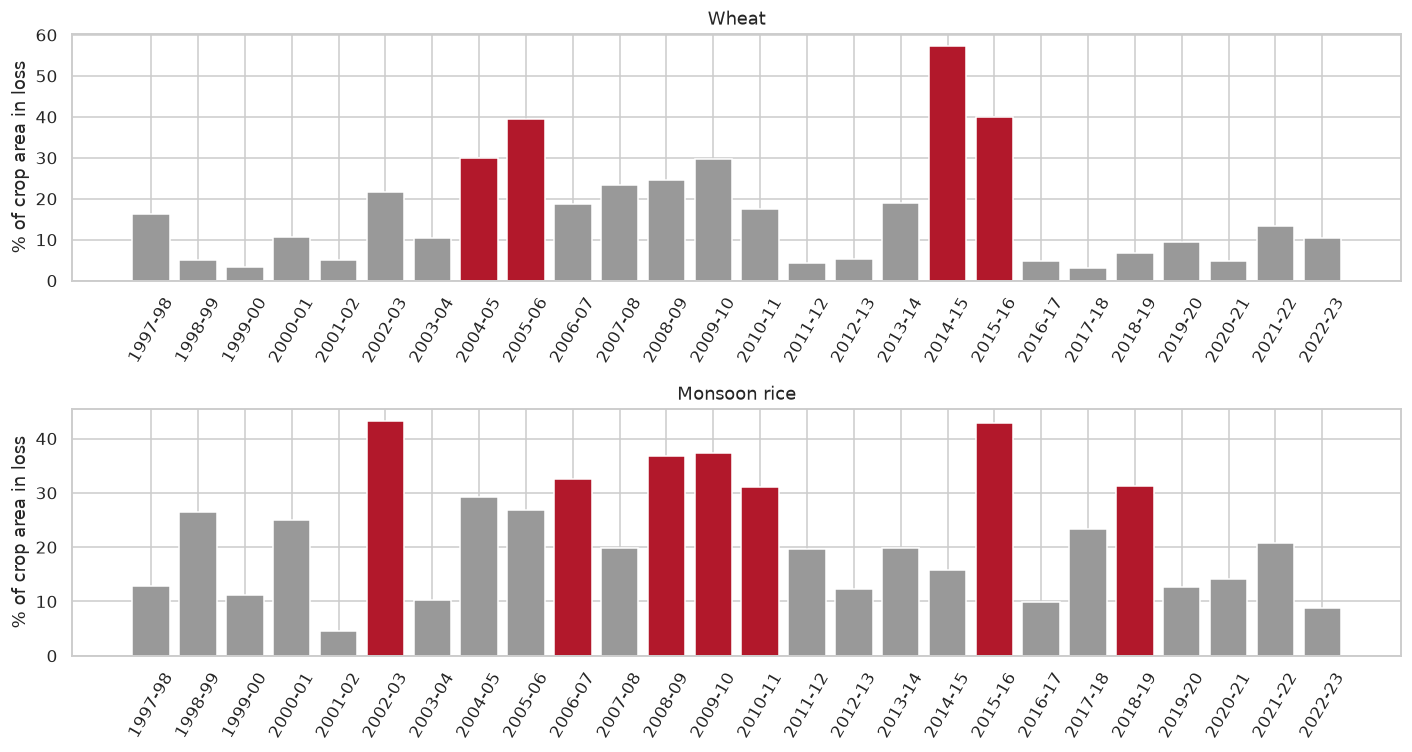

wheat  season  share_area_in_loss  mean_anomaly_pct
2014-15               0.574           -16.812
2015-16               0.398            -8.322
2005-06               0.394           -10.373
2004-05               0.300            -6.869
2009-10               0.296            -7.189
rice_monsoon  season  share_area_in_loss  mean_anomaly_pct
2002-03               0.433           -10.798
2015-16               0.429           -11.367
2009-10               0.373            -9.873
2008-09               0.369            -6.780
2006-07               0.326            -3.865


In [2]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
for a, key, name in ((ax[0], "wheat", "Wheat"), (ax[1], "rice_monsoon", "Monsoon rice")):
    y = pd.read_csv(P / f"loss_by_year_{key}.csv")
    a.bar(y.year.map(season), y.share_area_in_loss * 100, color=np.where(y.share_area_in_loss > .3, "#b2182b", "#999"))
    a.set(ylabel="% of crop area in loss", title=name); a.tick_params(axis="x", rotation=60)
fig.tight_layout(); save(fig, "10_loss_by_season"); plt.show()
for key in ("wheat", "rice_monsoon"):
    print(key, pd.read_csv(P / f"loss_by_year_{key}.csv").assign(season=lambda d: d.year.map(season))
          .sort_values("share_area_in_loss", ascending=False).head(5)[["season", "share_area_in_loss", "mean_anomaly_pct"]].round(3).to_string(index=False))

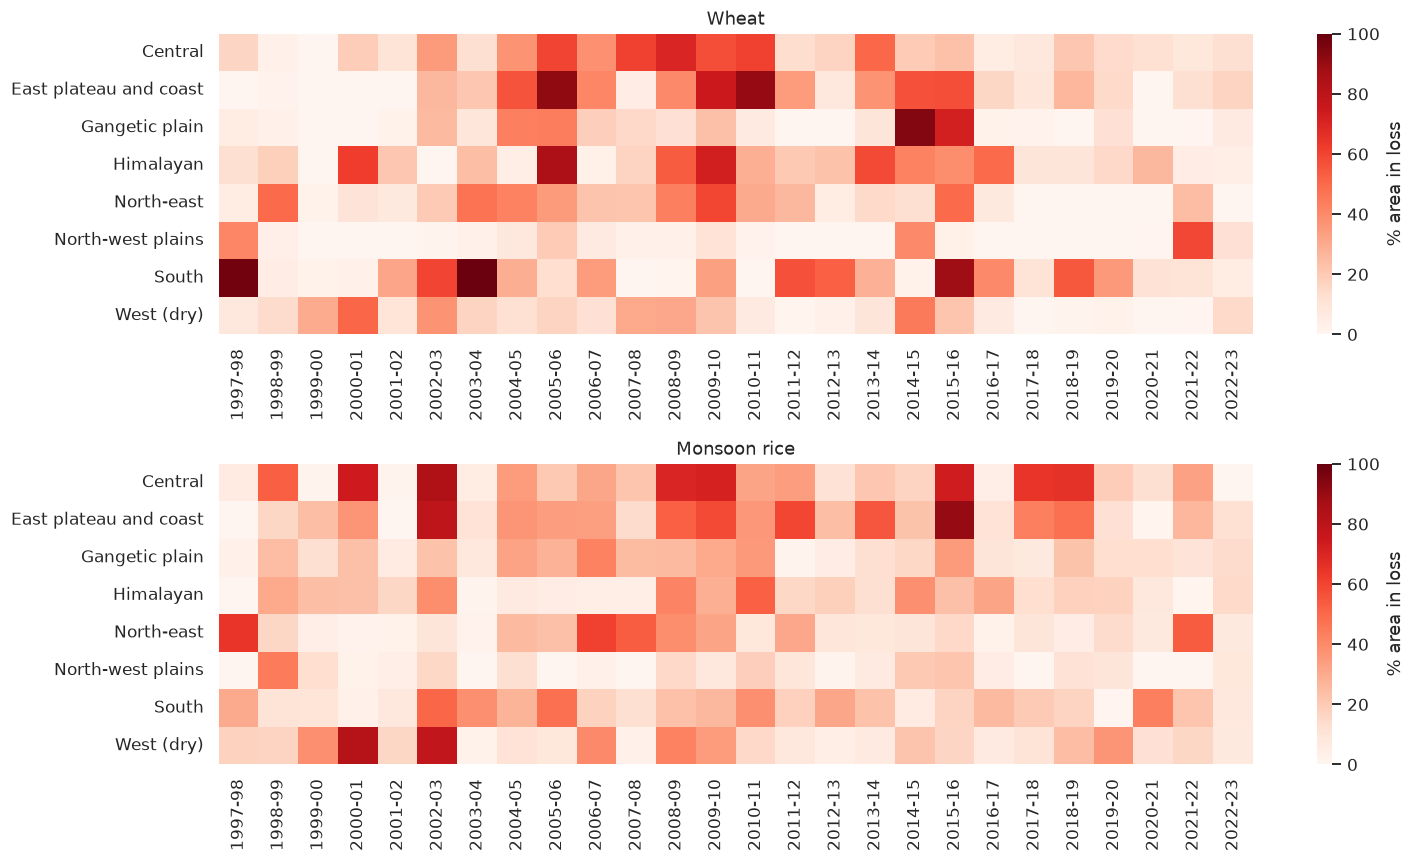

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8))
for a, key, name in ((ax[0], "wheat", "Wheat"), (ax[1], "rice_monsoon", "Monsoon rice")):
    r = pd.read_csv(P / f"loss_region_year_{key}.csv", index_col=0).drop(index="Other", errors="ignore") * 100
    r.columns = [season(c) for c in r.columns]
    sns.heatmap(r, cmap="Reds", vmin=0, vmax=100, ax=a, cbar_kws={"label": "% area in loss"}); a.set(title=name, ylabel="", xlabel="")
fig.tight_layout(); save(fig, "10_loss_region_season"); plt.show()

**Reading it.** Wheat failures cluster in a few seasons that hit several regions at once (2014-15, 2015-16,
2005-06); the north-west's worst is 2021-22. Rice failures line up with the official monsoon droughts (2002, 2009, 2015)
and hit Central India, the east and the dry west hardest.

## 2. What did the weather look like in loss seasons?

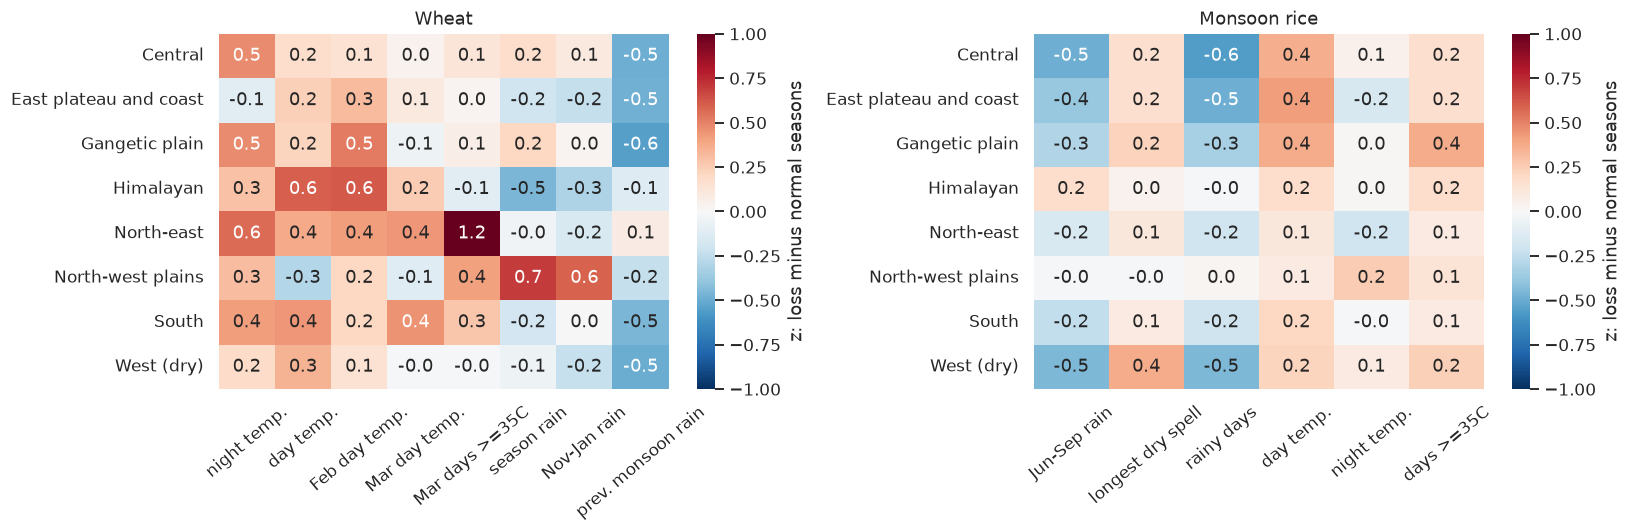

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, key, name in ((ax[0], "wheat", "Wheat"), (ax[1], "rice_monsoon", "Monsoon rice")):
    c = pd.read_csv(P / f"loss_weather_by_region_{key}.csv").set_index(["region", "loss"])
    d = (c.xs(1, level="loss") - c.xs(0, level="loss")).drop(index="Other", errors="ignore").rename(columns=LAB)
    sns.heatmap(d, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", ax=a,
                cbar_kws={"label": "z: loss minus normal seasons"}); a.set(title=name, ylabel="")
    a.tick_params(axis="x", rotation=40)
fig.tight_layout(); save(fig, "10_loss_weather_by_region"); plt.show()

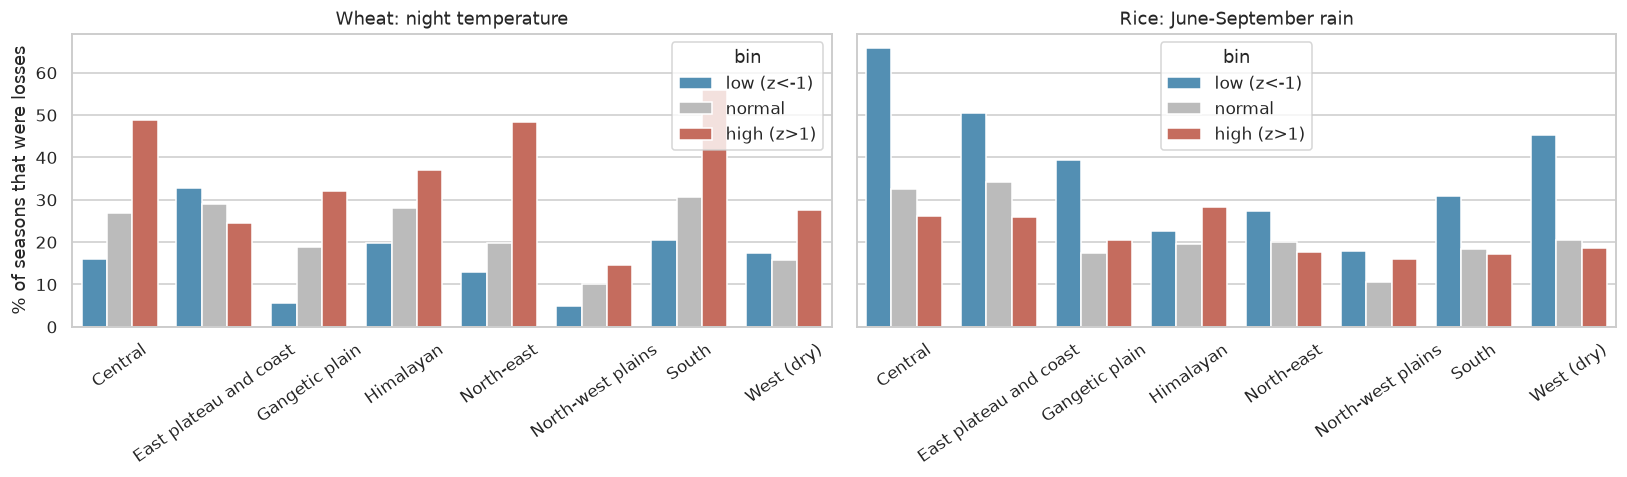

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, key, var, name in ((ax[0], "wheat", "tmin_mean", "Wheat: night temperature"), (ax[1], "rice_monsoon", "rain_jun_sep", "Rice: June-September rain")):
    b = pd.read_csv(P / f"loss_rate_by_weather_bin_{key}.csv")
    b = b[(b.variable == var) & (b.region != "Other")].melt(id_vars=["region", "variable"], var_name="bin", value_name="loss_rate")
    sns.barplot(b, x="region", y=b.loss_rate * 100, hue="bin", hue_order=["low (z<-1)", "normal", "high (z>1)"],
                palette=["#4393c3", "#bbbbbb", "#d6604d"], ax=a)
    a.set(title=name, xlabel="", ylabel="% of seasons that were losses"); a.tick_params(axis="x", rotation=35)
fig.tight_layout(); save(fig, "10_loss_rate_bins"); plt.show()

**Reading it.**
- *Wheat:* warm nights are the most consistent signal (7 of 8 regions); in the Gangetic plain 32% of warm-night seasons
  were losses against 6% of cool-night seasons. A weak preceding monsoon comes next (6 of 8 regions). A hot February
  matters in the Gangetic plain and the hills. In the irrigated north-west, losses come with *wet* seasons (harvest-time
  rain and hail, e.g. 2014-15). Only the east plateau and coast lose slightly more in cool seasons.
- *Rice:* rain dominates. When June-September rain is far below normal, loss rates jump (Central 66% vs 33% normally;
  east 51%; dry west 45%). Day heat in loss years mostly reflects sunny drought years. The irrigated north-west hardly
  reacts.
- Some losses have no weather signature (e.g. rice 2008 was wet and cool): pests, floods, input supply and reporting
  changes are not in public data.